# Mean-only BERT — Three-Seed Ablation

Classify relationships among retrieved documents into five CONFLICTS categories using question–document representations from `bert-base-uncased`. Each question–document pair is encoded separately with a 512-token maximum.

**Architecture:** Each question–document pair is encoded independently. The classifier averages document representations without a document-interaction Transformer or a max–min spread feature.

**Model settings:** `USE_INTERACTION=False`, `USE_SPREAD=False`. All four BERT variants share the same data split, input processing, optimizer, and training budget.

**Data:** `conflicts_621.jsonl` with the shared `conflicts_original_eval_split.json` manifest. Training uses 481 records (318 original and 163 synthetic); Validation uses 68 original records; Test uses 72 original records.

**Training:** Five-class classification with class-weighted cross-entropy loss; learning rate `1e-5`; batch size 1; gradient accumulation 4; maximum 8 epochs; early-stopping patience 3; training seeds 42, 43, and 44.

**Model selection:** Save the highest **four-class Validation Macro-F1**, averaged over labels 0–3. Misinformation (label 4) is excluded only from that average; the model still trains and predicts all five classes. Test labels are not used to select checkpoints.

**Evaluation:** Report Test accuracy, five-class and four-class Macro-F1, per-class precision/recall/F1/support, confusion matrices, and mean ± SD over three seeds. The original Misinformation class has one validation example and one test example, so its class-specific performance has high uncertainty.


In [ ]:
# Input and output directories for local and Kaggle execution
from pathlib import Path
import os

IS_KAGGLE = Path("/kaggle/input").is_dir()
if IS_KAGGLE:
    # Find the Kaggle dataset directory containing both required files.
    matching_dirs = sorted({
        p.parent for p in Path("/kaggle/input").rglob("conflicts_621.jsonl")
        if (p.parent / "conflicts_original_eval_split.json").is_file()
    })
    if len(matching_dirs) != 1:
        raise FileNotFoundError(
            f"Expected exactly one Kaggle dataset with both frozen files; found {matching_dirs}. "
            "Attach your private 'conflicts' dataset using Kaggle Add Input."
        )
    DATA_DIR = matching_dirs[0]
    OUTPUT_DIR = Path("/kaggle/working")
else:
    DATA_DIR = Path.cwd()
    OUTPUT_DIR = Path.cwd()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(OUTPUT_DIR)  # Write checkpoints and CSV files to the output directory
print("Input directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss

from transformers import BertTokenizer, BertModel

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight


Input directory: /kaggle/input/datasets/xiaominguo0222/conflicts
Output directory: /kaggle/working


## 1. Reproducibility and device


In [2]:
SEED = 42  # Initial random seed; training repeats with seeds 42, 43, and 44.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Load classification data

Load `conflicts_621.jsonl` and apply the fixed train, validation, and test indices from `conflicts_original_eval_split.json`. Dataset labels map to integers 0–4.


In [ ]:
# Load records in their original order.
DATA_PATH = str(DATA_DIR / "conflicts_621.jsonl")
with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = [json.loads(line) for line in f if line.strip()]

assert len(data) == 621, f"Expected 621 examples, found {len(data)}"
print("Loaded frozen dataset:", DATA_PATH)
print("Total examples:", len(data))

Loaded frozen dataset: /kaggle/input/datasets/xiaominguo0222/conflicts/conflicts_621.jsonl
Total examples: 621


In [5]:
print(data[0].keys())
print()

print("Question:")
print(data[0]["question"])

print("\nConflict type:")
print(data[0]["conflict_type"])

print("\nNumber of search results:")
print(len(data[0]["search_results"]))

dict_keys(['question', 'search_results', 'conflict_type'])

Question:
who is commander chief of the military

Conflict type:
Complementary information

Number of search results:
10


### Inspect an example


In [6]:
example_doc = data[0]["search_results"][0]

print("Document keys:")
print(example_doc.keys())

print("\nTitle:")
print(example_doc["title"])

print("\nShort text:")
print(example_doc["short_text"])

Document keys:
dict_keys(['title', 'short_text'])

Title:
Commander-in-chief - Wikipedia

Short text:
Accordingly, the Monarch is commander-in-chief of the Norwegian Armed Forces, and serves as chief diplomatic official abroad and as a symbol of unity.
 The President of the Republic, for a period of war, shall appoint the Commander-in-Chief of the Armed Forces on request of the Prime Minister. He may dismiss the Commander-in-Chief of the Armed Forces in accordance with the same procedure. The authority of the Commander-in-Chief of the Armed Forces, as well as the principle of his subordination to the constitutional organs of the Republic of Poland, shall be specified by statute.
 In the Portuguese military parlance, the term "Commander-in-Chief" (in Portuguese: comandante-em-chefe or simply comandante-chefe) refers to the unified military commander of all the land, naval and air forces in a theater of operations.
 Rwanda
Saudi Arabia
Article 60 of the Basic Law of Saudi Arabia states: 

### Five conflict categories


In [7]:
label2id = {
    "No conflict": 0,
    "Complementary information": 1,
    "Conflicting opinions and research outcomes": 2,
    "Conflict due to outdated information": 3,
    "Conflict due to misinformation": 4,
}

id2label = {
    0: "No Conflict",
    1: "Complementary",
    2: "Conflicting Opinions",
    3: "Outdated",
    4: "Misinformation",
}

labels = [item["conflict_type"] for item in data]

print(pd.Series(labels).value_counts())

No conflict                                   161
Complementary information                     115
Conflicting opinions and research outcomes    115
Conflict due to misinformation                115
Conflict due to outdated information          115
Name: count, dtype: int64


## 3. Model inputs and architecture

Each retrieved document is encoded jointly with the question (up to 512 tokens). Each question–document pair is encoded independently. The classifier averages document representations without a document-interaction Transformer or a max–min spread feature. The classifier outputs five logits, one per conflict category.


In [8]:
MODEL_NAME = "bert-base-uncased"
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)
MAX_LENGTH = 512


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
# Combine document title and text for BERT input.
def build_document_text(doc):
    title = doc.get("title", "") or ""
    short_text = doc.get("short_text", "") or ""
    return "Title: " + title + ". Text: " + short_text if short_text else "Title: " + title


In [10]:
# Quick check of one question-document pair
example_question = data[0]["question"]
example_text = build_document_text(data[0]["search_results"][0])
encoding = tokenizer(example_question, example_text, truncation="only_second", max_length=MAX_LENGTH)
print("Question:", example_question)
print("\nDocument:", example_text[:1500])
print("\nToken count:", len(encoding["input_ids"]))


Question: who is commander chief of the military

Document: Title: Commander-in-chief - Wikipedia. Text: Accordingly, the Monarch is commander-in-chief of the Norwegian Armed Forces, and serves as chief diplomatic official abroad and as a symbol of unity.
 The President of the Republic, for a period of war, shall appoint the Commander-in-Chief of the Armed Forces on request of the Prime Minister. He may dismiss the Commander-in-Chief of the Armed Forces in accordance with the same procedure. The authority of the Commander-in-Chief of the Armed Forces, as well as the principle of his subordination to the constitutional organs of the Republic of Poland, shall be specified by statute.
 In the Portuguese military parlance, the term "Commander-in-Chief" (in Portuguese: comandante-em-chefe or simply comandante-chefe) refers to the unified military commander of all the land, naval and air forces in a theater of operations.
 Rwanda
Saudi Arabia
Article 60 of the Basic Law of Saudi Arabia state

In [11]:
# Check document truncation
truncation_records = []
special_tokens = tokenizer.num_special_tokens_to_add(pair=True)

for example_id, item in enumerate(data):
    question = item["question"]
    question_ids = tokenizer.encode(question, add_special_tokens=False)

    for doc_id, doc in enumerate(item["search_results"]):
        document_text = build_document_text(doc)
        document_ids = tokenizer.encode(document_text, add_special_tokens=False)

        full_length = len(question_ids) + len(document_ids) + special_tokens
        available_document_tokens = MAX_LENGTH - len(question_ids) - special_tokens
        truncated_tokens = max(0, len(document_ids) - available_document_tokens)

        truncation_records.append({
            "example_id": example_id,
            "doc_id": doc_id,
            "label": item["conflict_type"],
            "question": question,
            "full_length": full_length,
            "document_tokens": len(document_ids),
            "truncated_tokens": truncated_tokens,
            "is_truncated": truncated_tokens > 0
        })

truncation_df = pd.DataFrame(truncation_records)

total_docs = len(truncation_df)
truncated_docs = truncation_df["is_truncated"].sum()

print("Total documents:", total_docs)
print("Truncated documents:", truncated_docs)
print("Truncation rate:", round(truncated_docs / total_docs * 100, 2), "%")

print("\nToken length summary:")
print(truncation_df["full_length"].describe())

print("\nTruncation by class:")
print(
    truncation_df.groupby("label")["is_truncated"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "documents", "sum": "truncated", "mean": "truncation_rate"})
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


Total documents: 5677
Truncated documents: 8
Truncation rate: 0.14 %

Token length summary:
count    5677.000000
mean      323.610534
std       143.354736
min        14.000000
25%       235.000000
50%       389.000000
75%       436.000000
max       558.000000
Name: full_length, dtype: float64

Truncation by class:
                                            documents  truncated  \
label                                                              
Complementary information                        1067          3   
Conflict due to misinformation                   1034          0   
Conflict due to outdated information             1054          0   
Conflicting opinions and research outcomes       1123          2   
No conflict                                      1399          3   

                                            truncation_rate  
label                                                        
Complementary information                          0.002812  
Conflict due to misin

In [12]:
# Convert classification examples to a DataFrame
rows = []

for item in data:
    rows.append({
        "question": item["question"],
        "documents": item["search_results"],
        "label": label2id[item["conflict_type"]]
    })

df = pd.DataFrame(rows)

assert len(df) == 621

print("Number of processed examples:", len(df))

print("\nLabel distribution:")
print(
    df["label"]
    .value_counts()
    .sort_index()
    .rename(index=id2label)
)

Number of processed examples: 621

Label distribution:
label
No Conflict             161
Complementary           115
Conflicting Opinions    115
Outdated                115
Misinformation          115
Name: count, dtype: int64


In [13]:
# Read shared Train / Validation / Test indices from the split manifest.
# Check that the manifest matches the loaded dataset and keeps splits disjoint.
import hashlib
SPLIT_MANIFEST_PATH = str(DATA_DIR / "conflicts_original_eval_split.json")
with open(SPLIT_MANIFEST_PATH, "r", encoding="utf-8") as f:
    split_manifest = json.load(f)
canonical = "\n".join(json.dumps(x, ensure_ascii=False, sort_keys=True) for x in data)
actual_sha256 = hashlib.sha256(canonical.encode("utf-8")).hexdigest()
assert actual_sha256 == split_manifest["dataset_sha256"], "Dataset differs from the dataset used to create the split manifest. Run 00_dataset_preparation first."
assert len(df) == 621
assert split_manifest["original_count"] == 458 and split_manifest["synthetic_count"] == 163
train_df = df.iloc[split_manifest["train_indices"]].copy().reset_index(drop=True)
val_df = df.iloc[split_manifest["validation_indices"]].copy().reset_index(drop=True)
test_df = df.iloc[split_manifest["test_indices"]].copy().reset_index(drop=True)
train_df["source"] = ["original" if i < 458 else "synthetic" for i in split_manifest["train_indices"]]
val_df["source"] = "original"
test_df["source"] = "original"
assert len(train_df) + len(val_df) + len(test_df) == 621
assert len(train_df) == len(split_manifest["train_indices"])
assert (val_df["source"] == "original").all() and (test_df["source"] == "original").all()
assert set(split_manifest["train_indices"]).isdisjoint(split_manifest["validation_indices"])
assert set(split_manifest["train_indices"]).isdisjoint(split_manifest["test_indices"])
print("Frozen data split:", len(train_df), len(val_df), len(test_df))
print("Train source counts:", train_df["source"].value_counts().to_dict())
print("Validation original labels:\n", val_df["label"].value_counts().sort_index().to_dict())
print("Test original labels:\n", test_df["label"].value_counts().sort_index().to_dict())
print("Warning: original misinformation has only 1 example in each evaluation split; per-class F1 is unreliable.")

Frozen data split: 481 68 72
Train source counts: {'original': 318, 'synthetic': 163}
Validation original labels:
 {0: 24, 1: 17, 2: 17, 3: 9, 4: 1}
Test original labels:
 {0: 25, 1: 18, 2: 18, 3: 10, 4: 1}


In [14]:
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))
assert len(train_df) + len(val_df) + len(test_df) == 621

print("\nTrain distribution:")
print(train_df["label"].value_counts().sort_index().rename(index=id2label))

print("\nValidation distribution:")
print(val_df["label"].value_counts().sort_index().rename(index=id2label))

print("\nTest distribution:")
print(test_df["label"].value_counts().sort_index().rename(index=id2label))

train_questions = set(train_df["question"].str.lower().str.strip())
val_questions = set(val_df["question"].str.lower().str.strip())
test_questions = set(test_df["question"].str.lower().str.strip())

assert len(train_questions & val_questions) == 0
assert len(train_questions & test_questions) == 0
assert len(val_questions & test_questions) == 0

print("\nBasic split checks passed.")

Train: 481 | Validation: 68 | Test: 72

Train distribution:
label
No Conflict             112
Complementary            80
Conflicting Opinions     80
Outdated                 96
Misinformation          113
Name: count, dtype: int64

Validation distribution:
label
No Conflict             24
Complementary           17
Conflicting Opinions    17
Outdated                 9
Misinformation           1
Name: count, dtype: int64

Test distribution:
label
No Conflict             25
Complementary           18
Conflicting Opinions    18
Outdated                10
Misinformation           1
Name: count, dtype: int64

Basic split checks passed.


In [15]:
# PyTorch Dataset: one example contains multiple question-document BERT inputs
class ConflictDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.dataframe = dataframe
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        question, documents, label = row["question"], row["documents"], row["label"]
        all_input_ids, all_attention_masks = [], []

        for doc in documents:
            document_text = build_document_text(doc)
            encoding = self.tokenizer(question, document_text, padding="max_length", truncation="only_second", max_length=self.max_length, return_tensors="pt")
            all_input_ids.append(encoding["input_ids"].squeeze(0))
            all_attention_masks.append(encoding["attention_mask"].squeeze(0))

        return {"input_ids": torch.stack(all_input_ids), "attention_mask": torch.stack(all_attention_masks), "label": torch.tensor(label, dtype=torch.long)}


In [16]:
# Pad the number of documents inside each batch
def collate_fn(batch):
    batch_size = len(batch)
    max_docs = max(item["input_ids"].size(0) for item in batch)
    seq_length = batch[0]["input_ids"].size(1)

    batch_input_ids = torch.full((batch_size, max_docs, seq_length), tokenizer.pad_token_id, dtype=torch.long)
    batch_attention_masks = torch.zeros((batch_size, max_docs, seq_length), dtype=torch.long)
    document_mask = torch.zeros((batch_size, max_docs), dtype=torch.float)
    labels = []

    for i, item in enumerate(batch):
        num_docs = item["input_ids"].size(0)
        batch_input_ids[i, :num_docs] = item["input_ids"]
        batch_attention_masks[i, :num_docs] = item["attention_mask"]
        document_mask[i, :num_docs] = 1
        labels.append(item["label"])

    return {"input_ids": batch_input_ids, "attention_mask": batch_attention_masks, "document_mask": document_mask, "label": torch.stack(labels)}


In [17]:
# Datasets and DataLoaders
train_dataset = ConflictDataset(train_df, tokenizer, MAX_LENGTH)
val_dataset = ConflictDataset(val_df, tokenizer, MAX_LENGTH)
test_dataset = ConflictDataset(test_df, tokenizer, MAX_LENGTH)

BATCH_SIZE = 1
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 481
Validation batches: 68
Test batches: 72


In [18]:
# Quick batch shape check
sample_batch = next(iter(train_loader))
print("input_ids:", sample_batch["input_ids"].shape)
print("attention_mask:", sample_batch["attention_mask"].shape)
print("document_mask:", sample_batch["document_mask"].shape)
print("label:", sample_batch["label"].shape)


input_ids: torch.Size([1, 10, 512])
attention_mask: torch.Size([1, 10, 512])
document_mask: torch.Size([1, 10])
label: torch.Size([1])


In [19]:
# Shared BERT architecture with optional interaction and spread features
class InteractionAwareBERT(torch.nn.Module):
    def __init__(
        self,
        model_name,
        num_labels=5,
        use_interaction=True,
        use_spread=True,
        num_heads=8,
        num_transformer_layers=1,
        dropout=0.1
    ):
        super().__init__()

        self.bert = BertModel.from_pretrained(model_name)
        self.hidden_size = self.bert.config.hidden_size

        self.use_interaction = use_interaction
        self.use_spread = use_spread

        if use_interaction:
            encoder_layer = torch.nn.TransformerEncoderLayer(
                d_model=self.hidden_size,
                nhead=num_heads,
                dim_feedforward=self.hidden_size * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True
            )

            self.document_encoder = torch.nn.TransformerEncoder(
                encoder_layer,
                num_layers=num_transformer_layers,
                enable_nested_tensor=False
            )

        classifier_input_size = self.hidden_size * 2 if use_spread else self.hidden_size

        self.dropout = torch.nn.Dropout(dropout)
        self.classifier = torch.nn.Linear(classifier_input_size, num_labels)

    def forward(self, input_ids, attention_mask, document_mask):
        batch_size, num_docs, seq_length = input_ids.shape

        flat_input_ids = input_ids.reshape(batch_size * num_docs, seq_length)
        flat_attention_mask = attention_mask.reshape(batch_size * num_docs, seq_length)

        outputs = self.bert(
            input_ids=flat_input_ids,
            attention_mask=flat_attention_mask
        )

        document_embeddings = outputs.last_hidden_state[:, 0, :]
        document_embeddings = document_embeddings.reshape(
            batch_size,
            num_docs,
            self.hidden_size
        )

        if self.use_interaction:
            padding_mask = document_mask == 0

            document_embeddings = self.document_encoder(
                document_embeddings,
                src_key_padding_mask=padding_mask
            )

        mask = document_mask.unsqueeze(-1)

        summed = (document_embeddings * mask).sum(dim=1)
        counts = document_mask.sum(dim=1, keepdim=True).clamp(min=1)
        mean_embedding = summed / counts

        if self.use_spread:
            valid_mask = document_mask.unsqueeze(-1).bool()

            max_embedding = document_embeddings.masked_fill(
                ~valid_mask,
                float("-inf")
            ).max(dim=1).values

            min_embedding = document_embeddings.masked_fill(
                ~valid_mask,
                float("inf")
            ).min(dim=1).values

            spread_embedding = max_embedding - min_embedding

            combined = torch.cat(
                [mean_embedding, spread_embedding],
                dim=1
            )
        else:
            combined = mean_embedding

        combined = self.dropout(combined)

        return self.classifier(combined)


In [20]:
USE_INTERACTION = False
USE_SPREAD = False

model = InteractionAwareBERT(
    MODEL_NAME,
    num_labels=5,
    use_interaction=USE_INTERACTION,
    use_spread=USE_SPREAD
).to(device)

print("Model variant:", "Mean-only")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model variant: Mean-only


In [21]:
# Quick model forward-pass check
sample_batch = next(iter(train_loader))

input_ids = sample_batch["input_ids"].to(device)
attention_mask = sample_batch["attention_mask"].to(device)
document_mask = sample_batch["document_mask"].to(device)

model.eval()

with torch.no_grad():
    logits = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        document_mask=document_mask
    )

print("Input shape:", input_ids.shape)
print("Document mask shape:", document_mask.shape)
print("Logits shape:", logits.shape)
print("Logits finite:", torch.isfinite(logits).all().item())

Input shape: torch.Size([1, 9, 512])
Document mask shape: torch.Size([1, 9])
Logits shape: torch.Size([1, 5])
Logits finite: True


In [22]:
# True class-weighted cross entropy.
# For BATCH_SIZE=1, reduction="mean" would cancel the sample's class weight.
# reduction="none" retains w_y * (-log p_y) for each example.
classes = np.array([0, 1, 2, 3, 4])
class_weights_np = compute_class_weight(
    class_weight="balanced", classes=classes, y=train_df["label"].values
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float, device=device)
for class_id, weight in zip(classes, class_weights_np):
    print(id2label[class_id], ":", round(float(weight), 4))

loss_function = CrossEntropyLoss(weight=class_weights, reduction="none")

def compute_loss(logits, labels):
    # batch mean of per-example weighted CE; works with gradient accumulation.
    return loss_function(logits, labels).mean()


No Conflict : 0.8589
Complementary : 1.2025
Conflicting Opinions : 1.2025
Outdated : 1.0021
Misinformation : 0.8513


In [23]:
# AdamW optimizer
LEARNING_RATE = 1e-5
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    foreach=False
)


In [ ]:
# Five-class predictions; checkpoint selection averages class F1 for labels 0–3.
MISINFORMATION_ID = label2id["Conflict due to misinformation"]
SELECTION_LABEL_IDS = [idx for idx in range(len(label2id)) if idx != MISINFORMATION_ID]
assert SELECTION_LABEL_IDS == [0, 1, 2, 3]

def four_class_macro_f1(y_true, y_pred):
    # Exclude Misinformation from the selection average while retaining five-class predictions.
    return f1_score(
        y_true, y_pred, labels=SELECTION_LABEL_IDS,
        average="macro", zero_division=0
    )

# Evaluation function
def evaluate_model(model, data_loader):
    model.eval()

    true_labels = []
    predictions = []

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            document_mask = batch["document_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                document_mask=document_mask
            )

            loss = compute_loss(logits, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

            predicted_labels = torch.argmax(logits, dim=1)

            true_labels.extend(labels.cpu().tolist())
            predictions.extend(predicted_labels.cpu().tolist())

    average_loss = total_loss / total_examples

    accuracy = accuracy_score(true_labels, predictions)
    macro_f1 = f1_score(
        true_labels,
        predictions,
        labels=list(range(5)),
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1, true_labels, predictions

In [25]:
# Train one model per seed (42, 43, 44) on the shared training split.
TRAIN_SEEDS = [42, 43, 44]
# Use 8 maximum epochs and early-stopping patience 3.
EPOCHS = 8
PATIENCE = 3
ACCUMULATION_STEPS = 4
run_results = []
run_histories = {}
test_per_class_rows = []

for train_seed in TRAIN_SEEDS:
    print(f"\n{'=' * 12} Training seed {train_seed} {'=' * 12}")
    random.seed(train_seed)
    np.random.seed(train_seed)
    torch.manual_seed(train_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(train_seed)

    # Recreate the shuffled loader, model and optimiser for each run.
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn
    )
    model = InteractionAwareBERT(
        MODEL_NAME, num_labels=5,
        use_interaction=USE_INTERACTION, use_spread=USE_SPREAD
    ).to(device)
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, foreach=False)

    # Train Mean-only BERT

    MODEL_TAG = f"interaction_{int(USE_INTERACTION)}_spread_{int(USE_SPREAD)}_original_eval"
    BEST_MODEL_PATH = f"best_{MODEL_TAG}_seed{train_seed}.pt"

    best_val_selection_f1_4 = -1.0
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": [],
        "val_selection_f1_4": []
    }

    for epoch in range(EPOCHS):
        print(f"\nEpoch {epoch + 1}/{EPOCHS}")

        model.train()
        optimizer.zero_grad()

        total_train_loss = 0.0
        total_examples = 0

        for step, batch in enumerate(train_loader):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            document_mask = batch["document_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                document_mask=document_mask
            )

            if not torch.isfinite(logits).all():
                raise RuntimeError(f"Non-finite logits for seed {train_seed}, epoch {epoch+1}, step {step+1}")
            loss = compute_loss(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss for seed {train_seed}, epoch {epoch+1}, step {step+1}")

            batch_size = labels.size(0)
            total_train_loss += loss.item() * batch_size
            total_examples += batch_size

            loss = loss / ACCUMULATION_STEPS
            loss.backward()
            for param_name, param in model.named_parameters():
                if param.grad is not None and not torch.isfinite(param.grad).all():
                    raise RuntimeError(
                        f"Non-finite gradient in {param_name}, seed {train_seed}, epoch {epoch+1}, step {step+1}"
                    )

            if (step + 1) % ACCUMULATION_STEPS == 0 or (step + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()
                for param_name, param in model.named_parameters():
                    if not torch.isfinite(param).all():
                        raise RuntimeError(
                            f"Non-finite parameter {param_name}, seed {train_seed}, epoch {epoch+1}, step {step+1}"
                        )
                optimizer.zero_grad()

        average_train_loss = total_train_loss / total_examples

        val_loss, val_accuracy, val_macro_f1, val_true, val_pred = evaluate_model(
            model,
            val_loader
        )
        val_selection_f1_4 = four_class_macro_f1(val_true, val_pred)

        history["train_loss"].append(average_train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_macro_f1)
        history["val_selection_f1_4"].append(val_selection_f1_4)

        print("Train loss:", round(average_train_loss, 4))
        print("Validation loss:", round(val_loss, 4))
        print("Validation accuracy:", round(val_accuracy, 4))
        print("Validation 5-class Macro-F1 (report):", round(val_macro_f1, 4))
        print("Validation 4-class Macro-F1 (selection):", round(val_selection_f1_4, 4))

        if val_selection_f1_4 > best_val_selection_f1_4:
            best_val_selection_f1_4 = val_selection_f1_4
            epochs_without_improvement = 0

            torch.save(model.state_dict(), BEST_MODEL_PATH)
            print("Best model saved.")

        else:
            epochs_without_improvement += 1

            print(
                "No improvement:",
                epochs_without_improvement,
                "/",
                PATIENCE
            )

            if epochs_without_improvement >= PATIENCE:
                print("Early stopping.")
                break

    print("\nBest validation 4-class Macro-F1 (selection):", round(best_val_selection_f1_4, 4))
    # Evaluate the checkpoint selected by four-class validation Macro-F1.
    model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True))
    model = model.to(device)
    test_loss, test_accuracy, test_macro_f1, test_true, test_pred = evaluate_model(model, test_loader)
    test_macro_f1_4 = four_class_macro_f1(test_true, test_pred)
    best_epoch = int(np.argmax(history["val_selection_f1_4"])) + 1
    best_val_macro_f1 = history["val_macro_f1"][best_epoch - 1]

    # Record Test predictions and per-class scores for each training seed.
    test_predictions_df = test_df[["question"]].copy().reset_index(drop=True)
    test_predictions_df["true_label"] = test_true
    test_predictions_df["predicted_label"] = test_pred
    test_predictions_df["true_class"] = [id2label[x] for x in test_true]
    test_predictions_df["predicted_class"] = [id2label[x] for x in test_pred]
    test_predictions_df.to_csv(f"{MODEL_TAG}_seed{train_seed}_test_predictions.csv", index=False)

    test_report = classification_report(
        test_true, test_pred, labels=list(range(5)),
        target_names=[id2label[i] for i in range(5)],
        output_dict=True, zero_division=0
    )
    for class_id in range(5):
        class_name = id2label[class_id]
        test_per_class_rows.append({
            "seed": train_seed, "class": class_name,
            "precision": test_report[class_name]["precision"],
            "recall": test_report[class_name]["recall"],
            "f1": test_report[class_name]["f1-score"],
            "support": test_report[class_name]["support"]
        })
    pd.DataFrame(
        confusion_matrix(test_true, test_pred, labels=list(range(5))),
        index=[id2label[i] for i in range(5)],
        columns=[id2label[i] for i in range(5)]
    ).to_csv(f"{MODEL_TAG}_seed{train_seed}_test_confusion.csv")
    run_results.append({
        "model": MODEL_TAG, "seed": train_seed,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_val_macro_f1,
        "best_val_selection_f1_4": best_val_selection_f1_4,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "test_macro_f1": test_macro_f1,
        "test_macro_f1_4": test_macro_f1_4,
        "checkpoint": BEST_MODEL_PATH,
    })
    run_histories[train_seed] = {key: values.copy() for key, values in history.items()}
    pd.DataFrame({**history, "epoch": range(1, len(history["train_loss"]) + 1),
                  "seed": train_seed}).to_csv(
        f"{MODEL_TAG}_seed{train_seed}_history.csv", index=False
    )
    pd.DataFrame(run_results).to_csv(f"{MODEL_TAG}_runs.csv", index=False)
    pd.DataFrame(test_per_class_rows).to_csv(f"{MODEL_TAG}_test_per_class.csv", index=False)
    print(f"Seed {train_seed}: test 5-class Macro-F1 = {test_macro_f1:.4f}; 4-class auxiliary = {test_macro_f1_4:.4f}")

# Summarize results across seeds; SD is the sample standard deviation (ddof=1).
runs_df = pd.DataFrame(run_results)
summary_rows = []
for metric in ["test_accuracy", "test_macro_f1", "test_macro_f1_4", "best_val_macro_f1", "best_val_selection_f1_4"]:
    summary_rows.append({
        "model": MODEL_TAG, "metric": metric, "n_runs": len(runs_df),
        "mean": runs_df[metric].mean(),
        "sd": runs_df[metric].std(ddof=1),
        "mean_pm_sd": f"{runs_df[metric].mean():.4f} ± {runs_df[metric].std(ddof=1):.4f}",
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f"{MODEL_TAG}_summary.csv", index=False)
print("\nThree-seed results:")
print(runs_df.to_string(index=False))
print("\nMean ± SD:")
print(summary_df[["metric", "mean_pm_sd"]].to_string(index=False))

# Diagnostic plots below use the checkpoint selected by DIAGNOSTIC_SEED.



============ Training seed 42 ============


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/8
Train loss: 1.1517
Validation loss: 1.1353
Validation accuracy: 0.5147
Validation 5-class Macro-F1 (report): 0.4098
Validation 4-class Macro-F1 (selection): 0.5123
Best model saved.

Epoch 2/8
Train loss: 0.7339
Validation loss: 1.2103
Validation accuracy: 0.5294
Validation 5-class Macro-F1 (report): 0.4199
Validation 4-class Macro-F1 (selection): 0.5248
Best model saved.

Epoch 3/8
Train loss: 0.6285
Validation loss: 1.378
Validation accuracy: 0.5
Validation 5-class Macro-F1 (report): 0.3964
Validation 4-class Macro-F1 (selection): 0.4955
No improvement: 1 / 3

Epoch 4/8
Train loss: 0.5183
Validation loss: 1.1895
Validation accuracy: 0.5
Validation 5-class Macro-F1 (report): 0.3994
Validation 4-class Macro-F1 (selection): 0.4992
No improvement: 2 / 3

Epoch 5/8
Train loss: 0.387
Validation loss: 1.8032
Validation accuracy: 0.4265
Validation 5-class Macro-F1 (report): 0.3392
Validation 4-class Macro-F1 (selection): 0.4241
No improvement: 3 / 3
Early stopping.

Best validatio

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/8
Train loss: 1.2052
Validation loss: 1.2439
Validation accuracy: 0.4559
Validation 5-class Macro-F1 (report): 0.3536
Validation 4-class Macro-F1 (selection): 0.442
Best model saved.

Epoch 2/8
Train loss: 0.7263
Validation loss: 1.1128
Validation accuracy: 0.5294
Validation 5-class Macro-F1 (report): 0.4157
Validation 4-class Macro-F1 (selection): 0.5197
Best model saved.

Epoch 3/8
Train loss: 0.57
Validation loss: 1.0365
Validation accuracy: 0.6176
Validation 5-class Macro-F1 (report): 0.4834
Validation 4-class Macro-F1 (selection): 0.6043
Best model saved.

Epoch 4/8
Train loss: 0.4746
Validation loss: 1.1402
Validation accuracy: 0.5882
Validation 5-class Macro-F1 (report): 0.4217
Validation 4-class Macro-F1 (selection): 0.5271
No improvement: 1 / 3

Epoch 5/8
Train loss: 0.3408
Validation loss: 1.6022
Validation accuracy: 0.4853
Validation 5-class Macro-F1 (report): 0.4103
Validation 4-class Macro-F1 (selection): 0.5128
No improvement: 2 / 3

Epoch 6/8
Train loss: 0.2192


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/8
Train loss: 1.2049
Validation loss: 1.1614
Validation accuracy: 0.5735
Validation 5-class Macro-F1 (report): 0.4405
Validation 4-class Macro-F1 (selection): 0.5506
Best model saved.

Epoch 2/8
Train loss: 0.7352
Validation loss: 1.1295
Validation accuracy: 0.5441
Validation 5-class Macro-F1 (report): 0.416
Validation 4-class Macro-F1 (selection): 0.5201
No improvement: 1 / 3

Epoch 3/8
Train loss: 0.6082
Validation loss: 1.1196
Validation accuracy: 0.5882
Validation 5-class Macro-F1 (report): 0.4546
Validation 4-class Macro-F1 (selection): 0.5682
Best model saved.

Epoch 4/8
Train loss: 0.5098
Validation loss: 1.2055
Validation accuracy: 0.5588
Validation 5-class Macro-F1 (report): 0.44
Validation 4-class Macro-F1 (selection): 0.55
No improvement: 1 / 3

Epoch 5/8
Train loss: 0.3539
Validation loss: 1.4651
Validation accuracy: 0.5441
Validation 5-class Macro-F1 (report): 0.4465
Validation 4-class Macro-F1 (selection): 0.5581
No improvement: 2 / 3

Epoch 6/8
Train loss: 0.273

In [26]:
history_rows = []

for seed, h in sorted(run_histories.items()):
    for idx in range(len(h["val_macro_f1"])):
        history_rows.append({
            "seed": seed,
            "epoch": idx + 1,
            "train_loss": h["train_loss"][idx],
            "val_loss": h["val_loss"][idx],
            "val_accuracy": h["val_accuracy"][idx],
            "val_macro_f1": h["val_macro_f1"][idx],
            "val_selection_f1_4": h["val_selection_f1_4"][idx],
        })

per_epoch_df = pd.DataFrame(history_rows)
display(per_epoch_df.round(4))

,seed,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_selection_f1_4
0,42,1,1.1517,1.1353,0.5147,0.4098,0.5123
1,42,2,0.7339,1.2103,0.5294,0.4199,0.5248
2,42,3,0.6285,1.3780,0.5000,0.3964,0.4955
3,42,4,0.5183,1.1895,0.5000,0.3994,0.4992
4,42,5,0.3870,1.8032,0.4265,0.3392,0.4241
5,43,1,1.2052,1.2439,0.4559,0.3536,0.4420
6,43,2,0.7263,1.1128,0.5294,0.4157,0.5197
7,43,3,0.5700,1.0365,0.6176,0.4834,0.6043
8,43,4,0.4746,1.1402,0.5882,0.4217,0.5271
9,43,5,0.3408,1.6022,0.4853,0.4103,0.5128


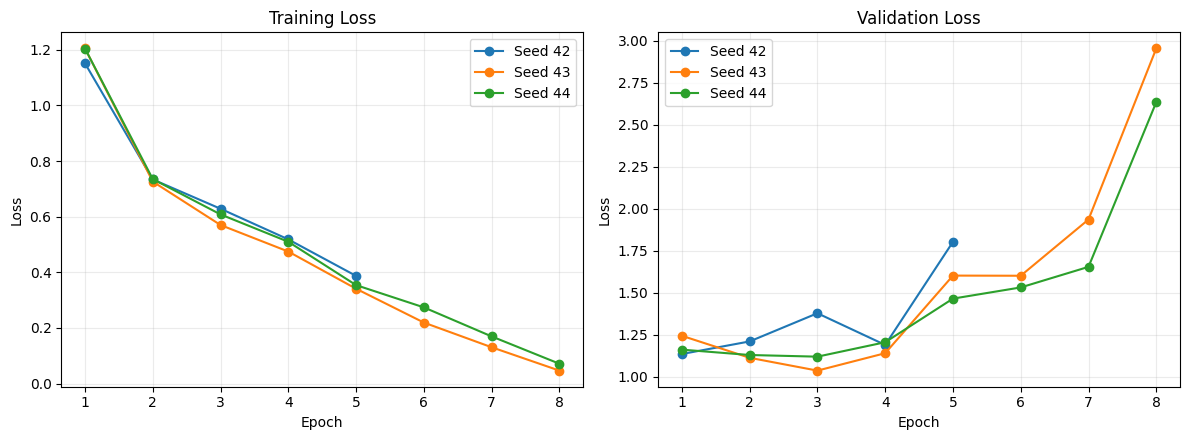

In [27]:
# Plot: training and validation loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for seed, h in sorted(run_histories.items()):
    epochs = range(1, len(h["train_loss"]) + 1)

    axes[0].plot(
        epochs, h["train_loss"],
        marker="o", label=f"Seed {seed}"
    )

    axes[1].plot(
        epochs, h["val_loss"],
        marker="o", label=f"Seed {seed}"
    )

for ax, title in zip(
    axes, ["Training Loss", "Validation Loss"]
):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

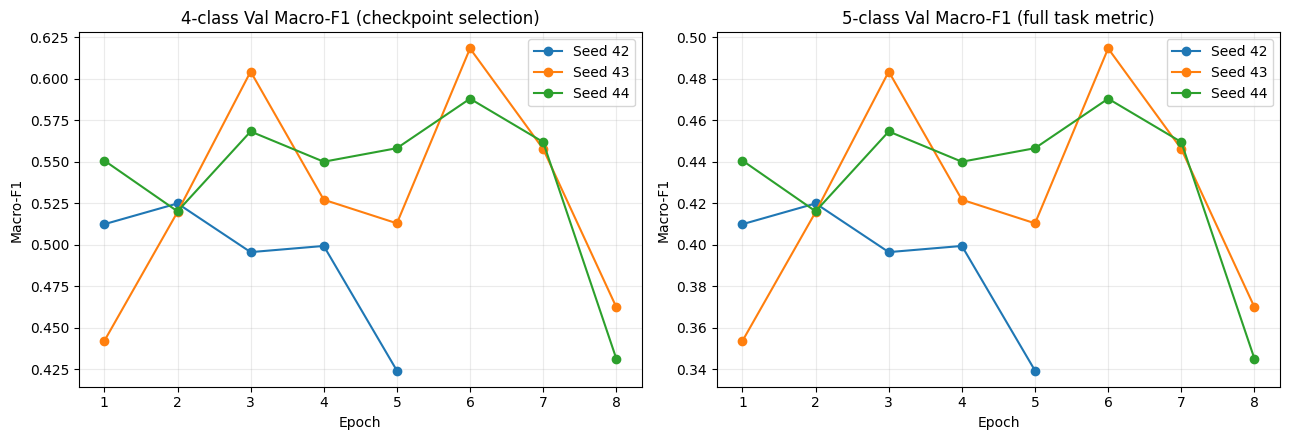

In [28]:
# Plot four-class selection F1 and five-class reporting F1 by epoch.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for seed, h in sorted(run_histories.items()):
    epochs = range(1, len(h["val_selection_f1_4"]) + 1)
    axes[0].plot(epochs, h["val_selection_f1_4"], marker="o", label=f"Seed {seed}")
    axes[1].plot(epochs, h["val_macro_f1"], marker="o", label=f"Seed {seed}")
axes[0].set_title("4-class Val Macro-F1 (checkpoint selection)")
axes[1].set_title("5-class Val Macro-F1 (full task metric)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [29]:
# Select a trained seed for detailed Test diagnostics.
# Load its saved best-validation checkpoint.
DIAGNOSTIC_SEED = 42  # Detailed diagnostic seed
DIAGNOSTIC_PATH = runs_df.set_index("seed").loc[DIAGNOSTIC_SEED, "checkpoint"]
model = InteractionAwareBERT(
    MODEL_NAME, num_labels=5,
    use_interaction=USE_INTERACTION, use_spread=USE_SPREAD
).to(device)
model.load_state_dict(torch.load(DIAGNOSTIC_PATH, map_location=device, weights_only=True))
model.eval()
print(f"Diagnostics: seed {DIAGNOSTIC_SEED}, checkpoint {DIAGNOSTIC_PATH}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Diagnostics: seed 42, checkpoint best_interaction_0_spread_0_original_eval_seed42.pt


In [30]:
def get_predictions(model, data_loader):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            document_mask = batch["document_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                document_mask=document_mask
            )

            predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    return all_labels, all_predictions

In [31]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
train_true, train_pred = get_predictions(model, train_loader)

train_accuracy = accuracy_score(train_true, train_pred)
train_macro_f1 = f1_score(
    train_true,
    train_pred,
    average="macro",
    zero_division=0
)

print("Train Accuracy:", round(train_accuracy, 4))
print("Train Macro-F1:", round(train_macro_f1, 4))

print(
    classification_report(
        train_true,
        train_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No Conflict",
            "Complementary",
            "Conflicting Opinions",
            "Outdated",
            "Misinformation"
        ],
        zero_division=0
    )
)

Train Accuracy: 0.7297
Train Macro-F1: 0.6961
                      precision    recall  f1-score   support

         No Conflict       0.78      0.25      0.38       112
       Complementary       0.66      0.55      0.60        80
Conflicting Opinions       0.59      0.96      0.73        80
            Outdated       0.69      0.96      0.80        96
      Misinformation       0.97      0.97      0.97       113

            accuracy                           0.73       481
           macro avg       0.74      0.74      0.70       481
        weighted avg       0.75      0.73      0.70       481



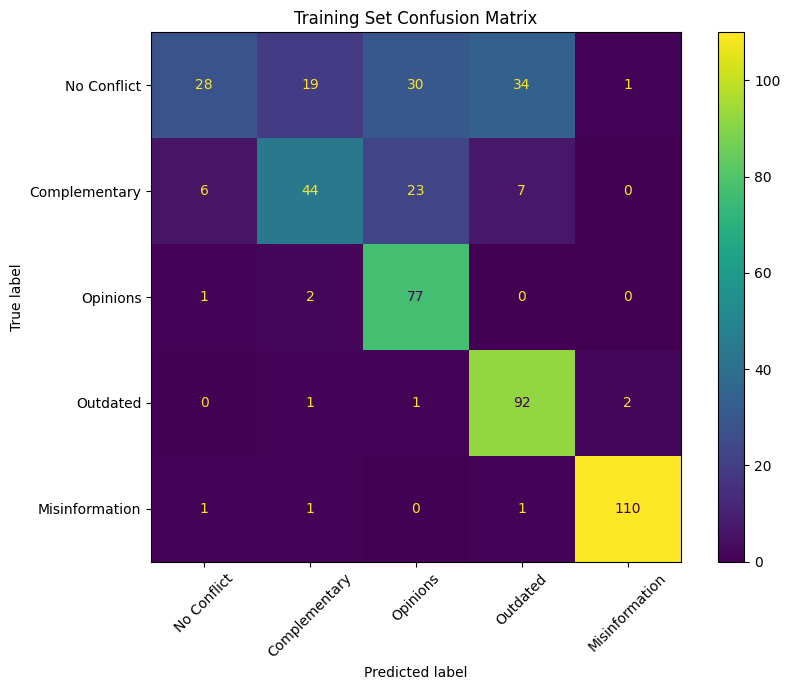

In [32]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
train_cm = confusion_matrix(
    train_true,
    train_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=[
        "No Conflict",
        "Complementary",
        "Opinions",
        "Outdated",
        "Misinformation"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("Training Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
val_true, val_pred = get_predictions(model, val_loader)

val_accuracy = accuracy_score(val_true, val_pred)
val_macro_f1 = f1_score(
    val_true,
    val_pred,
    average="macro",
    zero_division=0
)

print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation 5-class Macro-F1:", round(val_macro_f1, 4))
print("Validation 4-class Macro-F1 (selection):", round(four_class_macro_f1(val_true, val_pred), 4))

print(
    classification_report(
        val_true,
        val_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No Conflict",
            "Complementary",
            "Conflicting Opinions",
            "Outdated",
            "Misinformation"
        ],
        zero_division=0
    )
)

Validation Accuracy: 0.5294
Validation 5-class Macro-F1: 0.4199
Validation 4-class Macro-F1 (selection): 0.5248
                      precision    recall  f1-score   support

         No Conflict       0.40      0.17      0.24        24
       Complementary       0.64      0.53      0.58        17
Conflicting Opinions       0.65      0.88      0.75        17
            Outdated       0.38      0.89      0.53         9
      Misinformation       0.00      0.00      0.00         1

            accuracy                           0.53        68
           macro avg       0.42      0.49      0.42        68
        weighted avg       0.52      0.53      0.49        68



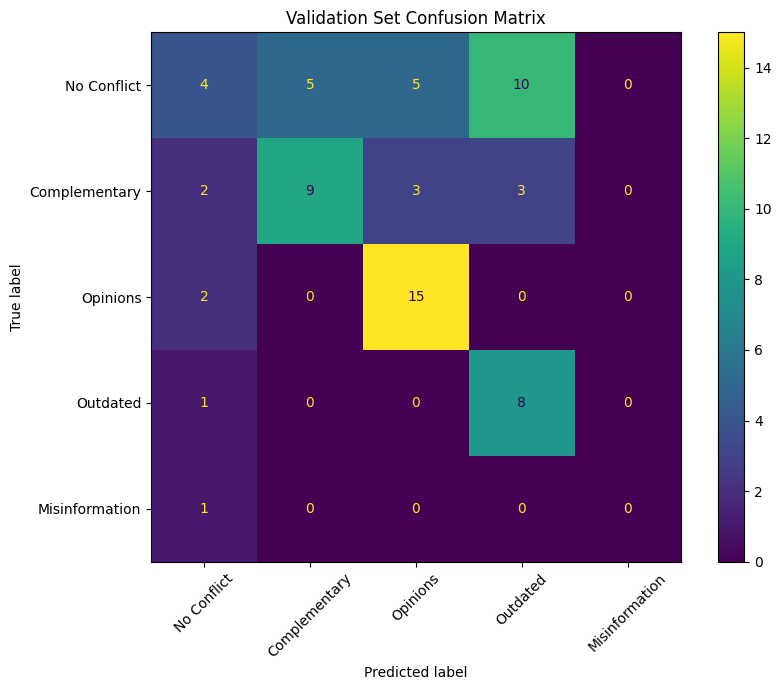

In [34]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
val_cm = confusion_matrix(
    val_true,
    val_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=[
        "No Conflict",
        "Complementary",
        "Opinions",
        "Outdated",
        "Misinformation"
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("Validation Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [35]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Internal test evaluation
test_loss, test_accuracy, test_macro_f1, y_true, y_pred = evaluate_model(model, test_loader)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test 5-class Macro-F1:", round(test_macro_f1, 4))
print("Test 4-class Macro-F1 (auxiliary):", round(four_class_macro_f1(y_true, y_pred), 4))


Test Loss: 1.1103
Test Accuracy: 0.5139
Test 5-class Macro-F1: 0.3981
Test 4-class Macro-F1 (auxiliary): 0.4976


In [36]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Per-class precision, recall and F1
target_names = [id2label[i] for i in range(5)]
print(classification_report(y_true, y_pred, labels=[0, 1, 2, 3, 4], target_names=target_names, zero_division=0))


                      precision    recall  f1-score   support

         No Conflict       0.60      0.12      0.20        25
       Complementary       0.67      0.44      0.53        18
Conflicting Opinions       0.64      0.89      0.74        18
            Outdated       0.34      1.00      0.51        10
      Misinformation       0.00      0.00      0.00         1

            accuracy                           0.51        72
           macro avg       0.45      0.49      0.40        72
        weighted avg       0.58      0.51      0.46        72



[[ 3  3  4 14  1]
 [ 1  8  5  4  0]
 [ 0  1 16  1  0]
 [ 0  0  0 10  0]
 [ 1  0  0  0  0]]


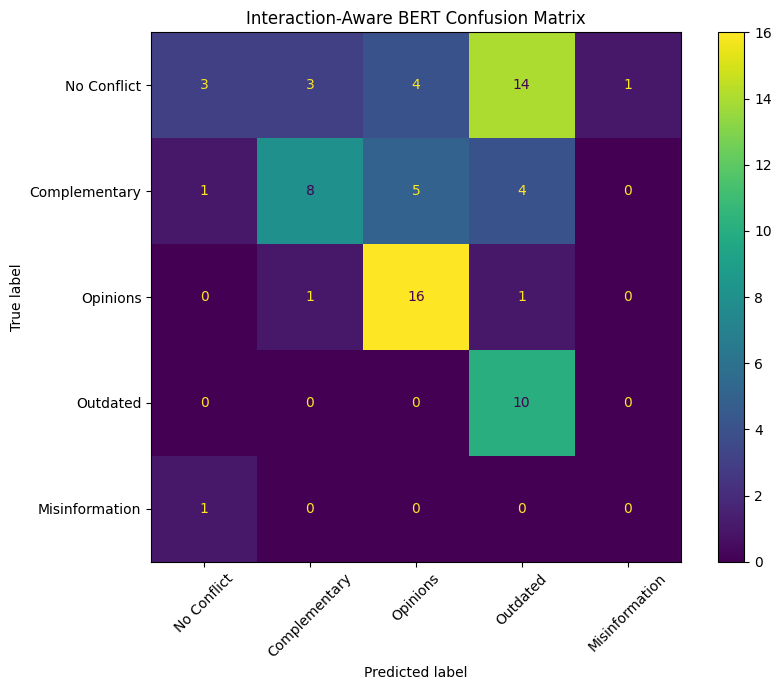

In [37]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Conflict", "Complementary", "Opinions", "Outdated", "Misinformation"])
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Interaction-Aware BERT Confusion Matrix")
plt.tight_layout()
plt.show()


In [38]:
# DIAGNOSTIC: seed selected by DIAGNOSTIC_SEED (seed 42)
# Error analysis
results_df = test_df.copy()
results_df["prediction"] = y_pred
results_df["true_name"] = results_df["label"].map(id2label)
results_df["predicted_name"] = results_df["prediction"].map(id2label)
wrong_predictions = results_df[results_df["label"] != results_df["prediction"]].copy()

print("Number of wrong predictions:", len(wrong_predictions))
display(wrong_predictions[["question", "true_name", "predicted_name"]].head(10))


Number of wrong predictions: 35


,question,true_name,predicted_name
0,when was coffee first made into a drink?,Complementary,Conflicting Opinions
1,Where did the expression a bridge too far come...,Misinformation,No Conflict
3,when was the last person executed,Complementary,Outdated
4,How many times csk reached final in ipl?,No Conflict,Outdated
5,How many cities in india has metro train?,Complementary,Outdated
7,What is the title of Stephen King's most recen...,No Conflict,Outdated
10,who has the most green jackets from the masters?,No Conflict,Outdated
11,who has the highest paid contract in the nba,No Conflict,Outdated
12,Does the Y chromosome determine only the male ...,Complementary,Conflicting Opinions
13,Can the 'big bang' theory and creationism coex...,No Conflict,Conflicting Opinions


## 4. Validation diagnostics across training seeds

Evaluate the best validation checkpoint from each training seed, reporting confusion matrices and per-class F1 scores. The single-seed diagnostics above use seed 42.


In [39]:
# Compute per-seed validation confusion matrices and class metrics from checkpoints
per_class_rows = []
for seed in TRAIN_SEEDS:
    path = runs_df.set_index("seed").loc[seed, "checkpoint"]
    diagnostic_model = InteractionAwareBERT(
        MODEL_NAME, num_labels=5,
        use_interaction=USE_INTERACTION, use_spread=USE_SPREAD
    ).to(device)
    diagnostic_model.load_state_dict(
        torch.load(path, map_location=device, weights_only=True)
    )
    true, pred = get_predictions(diagnostic_model, val_loader)
    report = classification_report(
        true, pred, labels=list(range(5)),
        target_names=[id2label[i] for i in range(5)],
        output_dict=True, zero_division=0
    )
    for label in [id2label[i] for i in range(5)]:
        per_class_rows.append({
            "seed": seed, "class": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": report[label]["support"]
        })
    print(f"\nSeed {seed}: validation confusion matrix")
    print(confusion_matrix(true, pred, labels=list(range(5))))
    del diagnostic_model
per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df.pivot(index="class", columns="seed", values="f1").round(3))
per_class_df.to_csv(f"{MODEL_TAG}_three_seed_validation_per_class.csv", index=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Seed 42: validation confusion matrix
[[ 4  5  5 10  0]
 [ 2  9  3  3  0]
 [ 2  0 15  0  0]
 [ 1  0  0  8  0]
 [ 1  0  0  0  0]]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Seed 43: validation confusion matrix
[[14  5  5  0  0]
 [ 1 15  1  0  0]
 [ 1  2 14  0  0]
 [ 7  0  0  2  0]
 [ 1  0  0  0  0]]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Seed 44: validation confusion matrix
[[14  1  5  4  0]
 [ 8  8  1  0  0]
 [ 3  0 14  0  0]
 [ 5  0  0  4  0]
 [ 1  0  0  0  0]]


seed,42,43,44
class,,,
Complementary,0.581,0.769,0.615
Conflicting Opinions,0.750,0.757,0.757
Misinformation,0.000,0.000,0.000
No Conflict,0.235,0.583,0.509
Outdated,0.533,0.364,0.471
